<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/jumping_pendulum_soft_hard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Jumping Pendulum Spatial Trajectories Soft vs Stiff Strings.

Simulating Soft Bungee Cord (k = 200)...
Simulating Stiff Steel Cable (k = 10000)...


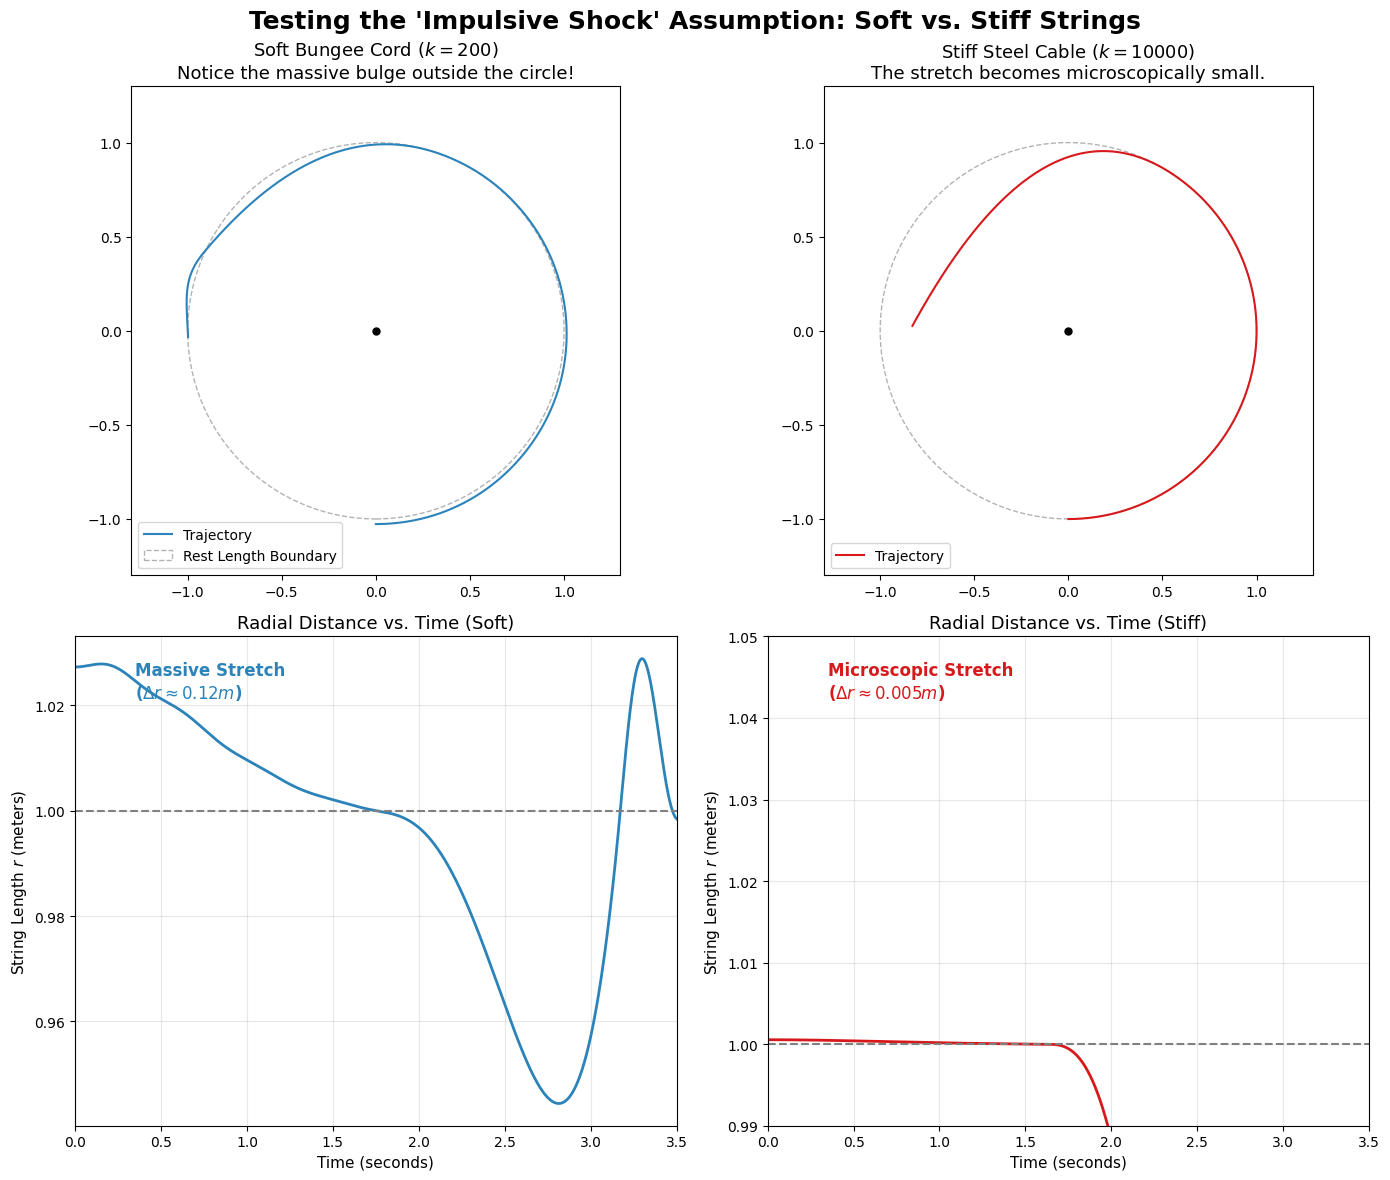

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Physics Constants
g = 1.0
L = 1.0
m = 1.0

# We lock the damping ratio (zeta) to 0.1 for BOTH strings.
zeta = 0.1

def cartesian_spring_pendulum(t, state, k):
    """
    Simulates the elastic pendulum in pure Cartesian (X,Y) coordinates.
    This completely avoids the singularity (division by zero) that happens
    in polar coordinates when a free-falling mass passes near the origin!
    """
    x, y, vx, vy = state

    # Calculate current radial distance
    r = np.hypot(x, y)
    r = max(r, 1e-9) # Safety guard to prevent exact origin divide-by-zero

    # Calculate radial velocity (projection of velocity vector onto radial unit vector)
    vr = (x * vx + y * vy) / r

    # Calculate damping required to maintain the target zeta
    c = 2 * zeta * np.sqrt(m * k)

    # The string only applies tension if stretched
    if r > L:
        T = k * (r - L) + c * vr
        # A string cannot push, so tension cannot be negative
        if T < 0:
            T = 0.0
    else:
        T = 0.0

    # Cartesian Equations of Motion (Gravity acts on Y, Tension pulls inward)
    ax = -(T / m) * (x / r)
    ay = -(T / m) * (y / r) - g

    return [vx, vy, ax, ay]

# Initial State Calculations
u0 = 0.819
E_initial = 1.5 * u0
omega0 = np.sqrt(2 * (E_initial + g * L)) # Angular speed at the bottom

# CRITICAL FIX: The centrifugal force requires the string to be stretched even at the bottom.
# T = m * (v^2 / r + g). Since we launch from bottom, cos(theta) = 1.
T_initial = m * (L * omega0**2 + g)

t_span = (0, 3.5)
t_eval = np.linspace(t_span[0], t_span[1], 5000)

print("Simulating Soft Bungee Cord (k = 200)...")
k_soft = 200.0
r0_soft = L + T_initial / k_soft
# Launch from bottom: x=0, y=-r. Tangent velocity is horizontal: vx=r*omega, vy=0
state0_soft = [0.0, -r0_soft, r0_soft * omega0, 0.0]

# Radau solver is excellent for stiff equations with abrupt switches (like slack strings)
sol_soft = solve_ivp(cartesian_spring_pendulum, t_span, state0_soft,
                     args=(k_soft,), t_eval=t_eval, method='Radau', rtol=1e-5, atol=1e-5)

print("Simulating Stiff Steel Cable (k = 10000)...")
k_stiff = 10000.0
r0_stiff = L + T_initial / k_stiff
state0_stiff = [0.0, -r0_stiff, r0_stiff * omega0, 0.0]

sol_stiff = solve_ivp(cartesian_spring_pendulum, t_span, state0_stiff,
                      args=(k_stiff,), t_eval=t_eval, method='Radau', rtol=1e-5, atol=1e-5)

# Extract spatial coordinates
x_soft, y_soft = sol_soft.y[0], sol_soft.y[1]
x_stiff, y_stiff = sol_stiff.y[0], sol_stiff.y[1]

# Calculate string length (r) over time for the bottom plots
r_soft = np.hypot(x_soft, y_soft)
r_stiff = np.hypot(x_stiff, y_stiff)

# ==========================================
# PLOTTING
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
plt.suptitle("Testing the 'Impulsive Shock' Assumption: Soft vs. Stiff Strings", fontsize=18, fontweight='bold')

# --- Top Left: Soft Spatial ---
axes[0,0].set_title("Soft Bungee Cord ($k=200$)\nNotice the massive bulge outside the circle!", fontsize=13)
axes[0,0].plot(x_soft, y_soft, color='#2b83ba', linewidth=1.5, label='Trajectory')
axes[0,0].add_patch(plt.Circle((0, 0), L, color='gray', fill=False, linestyle='--', alpha=0.6, label='Rest Length Boundary'))
axes[0,0].plot(0, 0, 'ko', markersize=5)
axes[0,0].set_aspect('equal')
axes[0,0].set_xlim(-1.3, 1.3)
axes[0,0].set_ylim(-1.3, 1.3)
axes[0,0].legend(loc='lower left')

# --- Top Right: Stiff Spatial ---
axes[0,1].set_title("Stiff Steel Cable ($k=10000$)\nThe stretch becomes microscopically small.", fontsize=13)
axes[0,1].plot(x_stiff, y_stiff, color='#d7191c', linewidth=1.5, label='Trajectory')
axes[0,1].add_patch(plt.Circle((0, 0), L, color='gray', fill=False, linestyle='--', alpha=0.6))
axes[0,1].plot(0, 0, 'ko', markersize=5)
axes[0,1].set_aspect('equal')
axes[0,1].set_xlim(-1.3, 1.3)
axes[0,1].set_ylim(-1.3, 1.3)
axes[0,1].legend(loc='lower left')

# --- Bottom Left: Soft Stretch vs Time ---
axes[1,0].plot(sol_soft.t, r_soft, color='#2b83ba', linewidth=2)
axes[1,0].set_title("Radial Distance vs. Time (Soft)", fontsize=13)
axes[1,0].set_ylabel("String Length $r$ (meters)", fontsize=11)
axes[1,0].set_xlabel("Time (seconds)", fontsize=11)
axes[1,0].axhline(L, color='gray', linestyle='--', label='Rest Length ($L=1$)')
axes[1,0].grid(True, alpha=0.3)
axes[1,0].set_xlim(0, 3.5)

# --- Bottom Right: Stiff Stretch vs Time ---
axes[1,1].plot(sol_stiff.t, r_stiff, color='#d7191c', linewidth=2)
axes[1,1].set_title("Radial Distance vs. Time (Stiff)", fontsize=13)
axes[1,1].set_ylabel("String Length $r$ (meters)", fontsize=11)
axes[1,1].set_xlabel("Time (seconds)", fontsize=11)
axes[1,1].axhline(L, color='gray', linestyle='--', label='Rest Length ($L=1$)')
axes[1,1].grid(True, alpha=0.3)
axes[1,1].set_xlim(0, 3.5)
axes[1,1].set_ylim(0.99, 1.05)

# Add annotations using axes fractional coordinates to prevent crash if data changes
axes[1,0].text(0.1, 0.95, 'Massive Stretch\n($\\Delta r \\approx 0.12m$)', transform=axes[1,0].transAxes,
               fontsize=12, fontweight='bold', va='top', ha='left', color='#2b83ba')
axes[1,1].text(0.1, 0.95, 'Microscopic Stretch\n($\\Delta r \\approx 0.005m$)', transform=axes[1,1].transAxes,
               fontsize=12, fontweight='bold', va='top', ha='left', color='#d7191c')

try:
    plt.tight_layout()
except ValueError:
    pass # Catch any extremely rare layout errors silently
plt.show()